IMPORT LIBRARIES AND INITIALIZE GEE

In [1]:
import ee

ee.Authenticate()

# Autenticar e inicializar Earth Engine
ee.Initialize(project='lips-482716')
print(ee.String('¡Conectado con éxito a los servidores de Earth Engine!').getInfo())

¡Conectado con éxito a los servidores de Earth Engine!


UPLOAD AND READ AOI GEOJSON

In [2]:
from google.colab import files

uploaded = files.upload()

Saving hebron_aoi.geojson to hebron_aoi.geojson


READ AND INSPECT AOI

In [3]:

import geopandas as gpd
import json
import ee

from shapely.geometry import mapping
from shapely import force_2d

# 1. Read GeoJSON
aoi_filename = next(iter(uploaded))
aoi_gdf = gpd.read_file(aoi_filename)

# 2. Inspect AOI
print("Number of features:", len(aoi_gdf))
print("CRS:", aoi_gdf.crs)
print("Geometry types:")
print(aoi_gdf.geom_type.value_counts())

# 3. Check geometry
geometry = aoi_gdf.geometry.iloc[0]

print("\nGeometry valid:", geometry.is_valid)
print("Geometry has Z coordinates:", geometry.has_z)
print("Geometry bounds:", geometry.bounds)

# 4. Ensure 2D coordinates
geometry_2d = force_2d(geometry)

# 5. Convert to GeoJSON geometry
aoi_geojson = mapping(geometry_2d)

# 6. Convert to Earth Engine geometry
aoi = ee.Geometry(
    aoi_geojson,
    proj="EPSG:4326",
    geodesic=False
)

# 7. Check AOI
print("\nAOI successfully converted to Earth Engine!")

area_km2 = aoi.area(maxError=10).divide(1e6).getInfo()

print("AOI area (km²):", round(area_km2, 2))


Number of features: 1
CRS: EPSG:4326
Geometry types:
MultiPolygon    1
Name: count, dtype: int64

Geometry valid: True
Geometry has Z coordinates: True
Geometry bounds: (34.92536803600007, 31.35535769100005, 35.26306375400003, 31.66552944100005)

AOI successfully converted to Earth Engine!
AOI area (km²): 674.49


LOAD LATEST SENTINEL-2 IMAGE

In [4]:
# Define geographical context (15 km buffer)
context_area = aoi.buffer(15000)

# Load Sentinel-2 collection
s2_collection = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(context_area)
    .filterDate("2026-09-17", "2026-11-17")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 50))
)

# Number of available images
n_images = s2_collection.size().getInfo()

print("Number of Sentinel-2 images:", n_images)

# Select latest acquisition
latest_image = ee.Image(
    s2_collection.sort("system:time_start", False).first()
)

# Get acquisition date and cloud cover
image_date = ee.Date(
    latest_image.get("system:time_start")
).format("YYYY-MM-dd").getInfo()

cloud_cover = latest_image.get(
    "CLOUDY_PIXEL_PERCENTAGE"
).getInfo()

print("Latest acquisition date:", image_date)
print("Cloud cover (%):", cloud_cover)

Number of Sentinel-2 images: 52
Latest acquisition date: 2026-11-15
Cloud cover (%): 0.282341


CREATE MOSAIC AND VISUALIZE AOI

In [5]:
import geemap

# Define daily time window around the latest acquisition
acquisition_date = ee.Date(
    latest_image.get("system:time_start")
)

start_date = acquisition_date.update(
    hour=0, minute=0, second=0
)

end_date = start_date.advance(1, "day")

# Create daily mosaic
daily_collection = s2_collection.filterDate(
    start_date, end_date
)

s2_image = daily_collection.mosaic()

# RGB visualization parameters (natural color)
rgb_vis = {
    "bands": ["B4", "B3", "B2"],
    "min": 0,
    "max": 3000,
    "gamma": 1.2
}

# Create interactive map
Map = geemap.Map()

# Center map on AOI
Map.centerObject(aoi, 9)

# Add Sentinel-2 image (regional context)
Map.addLayer(
    s2_image,
    rgb_vis,
    "Sentinel-2 RGB — " + image_date
)

# Add AOI boundary
Map.addLayer(
    aoi,
    {"color": "red"},
    "Hebron AOI"
)

# Display map
Map



Map(center=[31.48648212204845, 35.084251366078384], controls=(WidgetControl(options=['position', 'transparent_…

ANALYSIS CONFIGURATION

In [6]:

# Vegetation indices
INDEX = "MSAVI2"
COMPARE = ["NDVI", "SAVI", "MSAVI2", "EVI"]

# Temporal periods
BASE_YEARS = [2020, 2021, 2022]
TRANSITION_YEARS = [2023, 2024]
POST_YEARS = [2025, 2026]

# Dry season: June to September
DRY_START_MONTH = 6
DRY_START_DAY = 1

DRY_END_MONTH = 9
DRY_END_DAY = 30

# Spatial resolution (Sentinel-2)
SCALE = 10

# Study area
AOI = aoi

# Initial detection thresholds
BASE_MIN = {
    "NDVI": 0.25,
    "SAVI": 0.15,
    "MSAVI2": 0.14,
    "EVI": 0.13
}

STD_MAX = 0.06
DELTA_MIN = 0.05
Z_THR = 2.5
MIN_PX = 5
ANOM_THR = 0.06

print("Study area:", AOI.area(maxError=10).divide(1e6).getInfo(), "km²")
print("Baseline years:", BASE_YEARS)
print("Transition year:", TRANSITION_YEARS)
print("Post-escalation years:", POST_YEARS)
print("Main vegetation index:", INDEX)


Study area: 674.4924313012718 km²
Baseline years: [2020, 2021, 2022]
Transition year: [2023, 2024]
Post-escalation years: [2025, 2026]
Main vegetation index: MSAVI2


SENTINEL-2 PREPROCESSING


In [7]:

# PREPROCESSING, DRY-SEASON COMPOSITES AND INDICES

# 1. CLOUD MASKING AND BAND SELECTION

def prep(img):

    # Select SCL classification band
    scl = img.select("SCL")

    # Remove clouds, cloud shadows and snow
    good = (
        scl.neq(3)
        .And(scl.neq(7))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    # Select spectral bands, mask invalid pixels and scale reflectance
    bands = (
        img.select(["B2", "B3", "B4", "B8", "B11", "B12"])
        .updateMask(good)
        .divide(10000)
    )

    return bands.copyProperties(img, ["system:time_start"])


# 2. DRY-SEASON COMPOSITE FOR EACH YEAR

def dry_composite(year):

    start = ee.Date.fromYMD(year, 6, 1)
    end = ee.Date.fromYMD(year, 10, 1)

    composite = (
        S2.filterDate(start, end)
        .median()
        .set("year", year)
    )

    return composite


# 3. VEGETATION INDICES CALCULATED FROM THE COMPOSITE

def calculate_indices(composite):

    blue = composite.select("B2")
    red = composite.select("B4")
    nir = composite.select("B8")

    # NDVI
    ndvi = (
        nir.subtract(red)
        .divide(nir.add(red))
        .rename("NDVI")
    )

    # SAVI
    savi = composite.expression(
        "1.5 * (N - R) / (N + R + 0.5)",
        {"N": nir, "R": red}
    ).rename("SAVI")

    # MSAVI2
    msavi = composite.expression(
        "(2*N + 1 - sqrt((2*N + 1)*(2*N + 1) - 8*(N - R))) / 2",
        {"N": nir, "R": red}
    ).rename("MSAVI2")

    # EVI
    evi = composite.expression(
        "2.5 * (N - R) / (N + 6*R - 7.5*B + 1)",
        {"N": nir, "R": red, "B": blue}
    ).rename("EVI")

    return ee.Image.cat([ndvi, savi, msavi, evi])


In [8]:

# SENTINEL-2 IMAGE COLLECTION

S2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(AOI)
    .filterDate("2020-01-01", "2027-01-01")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 80))
    .map(prep)
)

n_images = S2.size().getInfo()

print("Number of Sentinel-2 images:", n_images)


Number of Sentinel-2 images: 2072


In [9]:
# GENERATE ALL YEARLY COMPOSITES AND INDICES

ALL_YEARS = BASE_YEARS + TRANSITION_YEARS + POST_YEARS

# Create one spectral composite for each year
composites = {}

# Calculate vegetation indices for each composite
yearly_indices = {}

for year in ALL_YEARS:

    composites[year] = dry_composite(year)

    yearly_indices[year] = calculate_indices(composites[year])

    print("Composite and indices created for:", year)

print("All yearly composites and indices generated.")


Composite and indices created for: 2020
Composite and indices created for: 2021
Composite and indices created for: 2022
Composite and indices created for: 2023
Composite and indices created for: 2024
Composite and indices created for: 2025
Composite and indices created for: 2026
All yearly composites and indices generated.


In [10]:
#  VISUALIZE YEARLY RGB COMPOSITES

rgb_vis = {
    "bands": ["B4", "B3", "B2"],
    "min": 0,
    "max": 0.3,
    "gamma": 1.2
}

Map_composites = geemap.Map()

Map_composites.centerObject(AOI, 10)

# Add yearly RGB composites
for year in ALL_YEARS:

    Map_composites.addLayer(
        composites[year],
        rgb_vis,
        f"RGB composite {year}",
        False
    )

# Add study area boundary
Map_composites.addLayer(
    AOI,
    {"color": "red"},
    "Hebron study area"
)

Map_composites


Map(center=[31.48648212204845, 35.084251366078384], controls=(WidgetControl(options=['position', 'transparent_…

In [11]:
index_vis = {
    "NDVI": {
        "min": 0.065,
        "max": 0.311,
        "palette": ["brown", "beige", "yellow", "green", "darkgreen"]
    },
    "SAVI": {
        "min": 0.061,
        "max": 0.225,
        "palette": ["brown", "beige", "yellow", "green", "darkgreen"]
    },
    "MSAVI2": {
        "min": 0.057,
        "max": 0.205,
        "palette": ["brown", "beige", "yellow", "green", "darkgreen"]
    },
    "EVI": {
        "min": 0.065,
        "max": 0.228,
        "palette": ["brown", "beige", "yellow", "green", "darkgreen"]
    }
}

In [12]:
# VISUALIZE VEGETATION INDICES (2020)

year = 2024

Map_indices = geemap.Map()
Map_indices.centerObject(AOI, 10)

for index in COMPARE:
    Map_indices.addLayer(
        yearly_indices[year].select(index),
        index_vis[index],
        f"{index} — {year}",
        index == INDEX
    )

# Convert geometry to FeatureCollection
AOI_outline = ee.FeatureCollection([ee.Feature(AOI)])

# Add ROI outline without fill
Map_indices.addLayer(
    AOI_outline.style(
        color="red",
        fillColor="00000000",
        width=2
    ),
    {},
    "Hebron study area"
)


Map_indices

Map(center=[31.48648212204844, 35.08425136607841], controls=(WidgetControl(options=['position', 'transparent_b…

In [13]:
# LAND COVER MASK
wc = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

# Select potentially relevant land-cover classes
lc_mask = (
    wc.eq(10)  # Tree cover
    .Or(wc.eq(20))  # Shrubland
    .Or(wc.eq(40))  # Cropland
)

print("ESA WorldCover loaded and land-cover mask created.")


ESA WorldCover loaded and land-cover mask created.


In [14]:
# VISUALIZE ESA WORLDCOVER MASK

Map_landcover = geemap.Map()
Map_landcover.centerObject(AOI, 10)

# Original land-cover classification
Map_landcover.addLayer(
    wc,
    {
        "min": 10,
        "max": 100,
        "palette": [
            "006400",  # Tree cover
            "ffbb22",  # Shrubland
            "ffff4c",  # Grassland
            "f096ff",  # Cropland
            "fa0000",
            "b4b4b4",
            "f0f0f0",
            "0064c8",
            "0096a0",
            "00cf75",
            "fae6a0"
        ]
    },
    "ESA WorldCover 2021",
    True
)

# Selected land-cover classes
Map_landcover.addLayer(
    lc_mask.selfMask(),
    {"palette": ["yellow"]},
    "Selected land-cover classes",
    False
)

Map_landcover.addLayer(
    AOI_outline.style(
        color="red",
        fillColor="00000000",
        width=2
    ),
    {},
    "Hebron study area"
)

Map_landcover

Map(center=[31.48648212204844, 35.08425136607841], controls=(WidgetControl(options=['position', 'transparent_b…

In [15]:
#  WORLD COVER CLASS DISTRIBUTION

class_counts = wc.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=AOI,
    scale=10,
    maxPixels=1e9
)

print(class_counts.getInfo())

{'Map': {'10': 165766.7294117647, '20': 1550437.0352941176, '30': 3165414.250980392, '40': 847207.4980392157, '50': 1237328.380392157, '60': 960811.7176470585, '80': 10}}


In [16]:
#  LAND COVER + DRY-SEASON GREENNESS

green_mask = yearly_indices[2020].select(INDEX).gte(BASE_MIN[INDEX])

candidate_mask = lc_mask.And(green_mask).selfMask()

Map_candidates = geemap.Map()
Map_candidates.centerObject(AOI, 10)

Map_candidates.addLayer(
    candidate_mask,
    {"palette": ["00AA00"]},
    "Potential olive grove areas",
    True
)

Map_candidates.addLayer(
    AOI_outline.style(
        color="red",
        fillColor="00000000",
        width=2
    ),
    {},
    "Hebron study area"
)

Map_candidates

Map(center=[31.48648212204844, 35.08425136607841], controls=(WidgetControl(options=['position', 'transparent_b…

In [17]:

#  TEMPORAL STATISTICS FUNCTION

def calculate_period_stats(years, index=INDEX):

    # Get the selected vegetation index for each year
    annual_images = [
        yearly_indices[year].select(index)
        for year in years
    ]

    # Create an ImageCollection
    collection = ee.ImageCollection.fromImages(annual_images)

    # Calculate temporal statistics
    mean = collection.mean().rename("mean")

    std = (
        collection
        .reduce(ee.Reducer.stdDev())
        .max(0.02)
        .rename("std")
    )

    return {
        "mean": mean,
        "std": std
    }


In [18]:
# CALCULATE PERIOD STATISTICS

reference = calculate_period_stats(BASE_YEARS)
transition = calculate_period_stats(TRANSITION_YEARS)
post = calculate_period_stats(POST_YEARS)

print("Temporal statistics calculated for all periods.")


Temporal statistics calculated for all periods.


In [19]:
# CANDIDATE OLIVE GROVE MASK

candidate_groves = (
    lc_mask
    .And(reference["mean"].gte(BASE_MIN[INDEX]))
    .And(reference["std"].lte(STD_MAX))
    .selfMask()
)

print("Candidate olive grove mask created.")


Candidate olive grove mask created.


In [20]:
# VISUALIZE REFERENCE PERIOD STATISTICS

Map_reference = geemap.Map()
Map_reference.centerObject(AOI, 10)

# Mean MSAVI2
Map_reference.addLayer(
    reference["mean"],
    {
        "min": 0,
        "max": 0.3,
        "palette": ["brown", "beige", "yellow", "green", "darkgreen"]
    },
    "Mean MSAVI2 (2020-2022)",
    True
)

# Standard deviation
Map_reference.addLayer(
    reference["std"],
    {
        "min": 0,
        "max": 0.15,
        "palette": ["green", "yellow", "red"]
    },
    "MSAVI2 standard deviation (2020-2022)",
    False
)

Map_reference.addLayer(
    AOI_outline.style(
        color="red",
        fillColor="00000000",
        width=2
    ),
    {},
    "Hebron study area"
)

Map_reference

Map(center=[31.48648212204844, 35.08425136607841], controls=(WidgetControl(options=['position', 'transparent_b…

In [21]:
# TEMPORAL CHANGE DETECTION

# Change relative to the reference period
transition_delta = (
    transition["mean"]
    .subtract(reference["mean"])
    .rename("transition_delta")
)

post_delta = (
    post["mean"]
    .subtract(reference["mean"])
    .rename("post_delta")
)

print("Temporal changes calculated.")


Temporal changes calculated.


In [22]:

#  VISUALIZE TEMPORAL CHANGES

# Combine existing 2025 and 2026 composites
test_rgb = ee.ImageCollection([
    composites[2025],
    composites[2026]
]).median()

Map_change = geemap.Map()
Map_change.centerObject(AOI, 10)

# RGB background visualization
rgb_vis = {
    "bands": ["B4", "B3", "B2"],
    "min": 0,
    "max": 0.3,
    "gamma": 1.2
}

# Change visualization
delta_vis = {
    "min": -0.2,
    "max": 0.2,
    "palette": ["red", "white", "green"]
}

# Background: RGB composite 2025-2026
Map_change.addLayer(
    test_rgb,
    rgb_vis,
    "RGB composite 2025-2026",
    True
)

# Transition period (optional)
# Map_change.addLayer(
#     transition_delta.updateMask(candidate_groves),
#     delta_vis,
#     "Change 2023-2024 vs 2020-2022",
#     False
# )

# Post period
Map_change.addLayer(
    post_delta.updateMask(candidate_groves),
    delta_vis,
    "Change 2025-2026 vs 2020-2022",
    True
)

# Study area boundary
Map_change.addLayer(
    AOI_outline.style(
        color="black",
        fillColor="00000000",
        width=2
    ),
    {},
    "Hebron study area"
)

Map_change


Map(center=[31.48648212204844, 35.08425136607841], controls=(WidgetControl(options=['position', 'transparent_b…

In [23]:
#  EXPORT CHANGE RASTER TO GOOGLE DRIVE

change_image = (
    post_delta
    .updateMask(candidate_groves)
    .rename("MSAVI2_change")
    .clip(AOI)
)

task = ee.batch.Export.image.toDrive(
    image=change_image,
    description="Hebron_MSAVI2_change_2025_2026",
    folder="EarthEngine",
    fileNamePrefix="Hebron_MSAVI2_change_2025_2026",
    region=AOI,
    scale=10,
    crs="EPSG:32636",
    maxPixels=1e13,
    fileFormat="GeoTIFF"
)

task.start()

print("Export started.")
print("Task ID:", task.id)

Export started.
Task ID: PQXTF35CKJFGOIHVEIPRO6HX


In [27]:
# CELL 23 — VISUALIZE TEMPORAL CHANGE WITH BROWN BACKGROUND

Map_change = geemap.Map()
Map_change.centerObject(AOI, 10)

# Original symmetric colour scale
delta_vis = {
    "min": -0.2,
    "max": 0.2,
    "palette": ["red", "white", "green"]
}

# Opaque brown background, restricted to the AOI
background = ee.Image.constant(1).clip(AOI)

Map_change.addLayer(
    background,
    {"min": 0, "max": 1, "palette": ["8B5A2B"]},
    "Background",
    True
)

# Change raster, restricted to the AOI and candidate areas
change_display = (
    post_delta
    .updateMask(candidate_groves)
    .clip(AOI)
)

Map_change.addLayer(
    change_display,
    delta_vis,
    "MSAVI2 change (2025-2026 vs 2020-2022)",
    True
)

# AOI outline
Map_change.addLayer(
    AOI_outline.style(
        color="black",
        fillColor="00000000",
        width=2
    ),
    {},
    "Hebron study area"
)

Map_change

Map(center=[31.48648212204845, 35.084251366078384], controls=(WidgetControl(options=['position', 'transparent_…

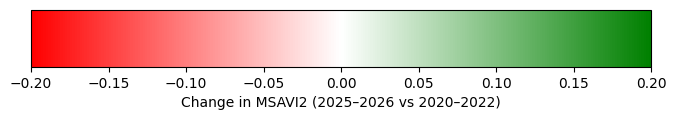

In [28]:
# COLOURBAR LEGEND

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

# Same palette and limits as the Earth Engine map
change_cmap = LinearSegmentedColormap.from_list(
    "MSAVI2_change",
    ["red", "white", "green"]
)

norm = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)

fig, ax = plt.subplots(figsize=(8, 1.5))

fig.subplots_adjust(bottom=0.5)

cbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=change_cmap),
    cax=ax,
    orientation="horizontal"
)

cbar.set_label(
    "Change in MSAVI2 (2025–2026 vs 2020–2022)"
)

plt.show()

In [29]:
# AREA OF VEGETATION CHANGE (MUTUALLY EXCLUSIVE CLASSES)

# 1. Significant decrease (<= -0.05)
significant_decline = (
    post_delta.lte(-DELTA_MIN)
    .And(candidate_groves)
)

# 2. Slight/Non-significant decrease (between -0.05 and 0)
slight_decline = (
    post_delta.gt(-DELTA_MIN)
    .And(post_delta.lt(0))
    .And(candidate_groves)
)

# 3. Slight/Non-significant increase (between 0 and 0.05)
slight_increase = (
    post_delta.gte(0)
    .And(post_delta.lt(DELTA_MIN))
    .And(candidate_groves)
)

# 4. Significant increase (>= 0.05)
significant_increase = (
    post_delta.gte(DELTA_MIN)
    .And(candidate_groves)
)

# Calculate area in km²
def calculate_area_km2(mask):
    area = (
        ee.Image.pixelArea()
        .updateMask(mask)
        .reduceRegion(
            reducer=ee.Reducer.sum(),
            geometry=AOI,
            scale=SCALE,
            maxPixels=1e13,
            tileScale=4
        )
        .get("area")
    )
    return ee.Number(area).divide(1e6).getInfo()

# Calculate mutually exclusive areas
sig_decline_km2 = calculate_area_km2(significant_decline)
sli_decline_km2 = calculate_area_km2(slight_decline)
sli_increase_km2 = calculate_area_km2(slight_increase)
sig_increase_km2 = calculate_area_km2(significant_increase)
total_calculated = sig_decline_km2 + sli_decline_km2 + sli_increase_km2 + sig_increase_km2

print(f"Umbral de significancia utilizado: {DELTA_MIN}\n")
print("1. Area with SIGNIFICANT decline (<= -0.05):", round(sig_decline_km2, 2), "km²")
print("2. Area with SLIGHT decline (>-0.05 and < 0):  ", round(sli_decline_km2, 2), "km²")
print("3. Area with SLIGHT increase (>= 0 and < 0.05): ", round(sli_increase_km2, 2), "km²")
print("4. Area with SIGNIFICANT increase (>= 0.05): ", round(sig_increase_km2, 2), "km²")
print("---------------------------------------------------")
print("Total area summed:", round(total_calculated, 2), "km²")


Umbral de significancia utilizado: 0.05

1. Area with SIGNIFICANT decline (<= -0.05): 10.33 km²
2. Area with SLIGHT decline (>-0.05 and < 0):   53.91 km²
3. Area with SLIGHT increase (>= 0 and < 0.05):  27.28 km²
4. Area with SIGNIFICANT increase (>= 0.05):  2.56 km²
---------------------------------------------------
Total area summed: 94.07 km²


In [30]:
# AREA OF CANDIDATE GROVES

candidate_area = (
    ee.Image.pixelArea()
    .updateMask(candidate_groves)
    .reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=AOI,
        scale=SCALE,
        maxPixels=1e13,
        tileScale=4
    )
    .get("area")
)

candidate_area_km2 = ee.Number(candidate_area).divide(1e6).getInfo()

print("AOI area:", round(AOI.area(maxError=10).divide(1e6).getInfo(), 2), "km²")
print("Candidate groves area:", round(candidate_area_km2, 2), "km²")
print("Percentage of AOI:", round(candidate_area_km2 / 674.49 * 100, 2), "%")

AOI area: 674.49 km²
Candidate groves area: 94.07 km²
Percentage of AOI: 13.95 %


In [31]:
# CREATE FOUR-CLASS CHANGE RASTER

# Threshold for relevant change
threshold = DELTA_MIN

# Start with an empty image that inherits the projection of post_delta
change_classes = post_delta.multiply(0).toByte()

# Class 1: Significant decrease (red)
change_classes = change_classes.where(
    post_delta.lte(-threshold), 1
)

# Class 2: Small decrease (orange)
change_classes = change_classes.where(
    post_delta.gt(-threshold).And(post_delta.lt(0)), 2
)

# Class 3: Small increase (blue)
change_classes = change_classes.where(
    post_delta.gte(0).And(post_delta.lt(threshold)), 3
)

# Class 4: Significant increase (green)
change_classes = change_classes.where(
    post_delta.gte(threshold), 4
)

# Apply candidate mask and restrict to the AOI
change_classes = (
    change_classes
    .updateMask(candidate_groves)
    .clip(AOI)
    .rename("change_class")
)

print("Four-class change raster created.")
print("Classification threshold:", threshold)

Four-class change raster created.
Classification threshold: 0.05


In [32]:
task = ee.batch.Export.image.toDrive(
    image=change_classes,
    description="Hebron_MSAVI2_Change_Classification",
    folder="EarthEngine",
    fileNamePrefix="Hebron_MSAVI2_Change_Classification",
    region=AOI,
    scale=10,
    crs="EPSG:32636",
    maxPixels=1e13,
    fileFormat="GeoTIFF",
    formatOptions={"cloudOptimized": True}
)

#task.start()

print("Export task started.")
print("Task ID:", task.id)

Export task started.
Task ID: None


In [ ]:
# CHECK EXPORT STATUS
print(task.status())

{'state': 'COMPLETED', 'description': 'Hebron_MSAVI2_Change_Classification', 'priority': 100, 'creation_timestamp_ms': 1794866838916, 'update_timestamp_ms': 1794868301690, 'start_timestamp_ms': 1794866981016, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://drive.google.com/#folders/1x3rGH5M4kclBQJgnDgD8gdqdNqxzW9cJ'], 'attempt': 4, 'batch_eecu_usage_seconds': 6642.74658203125, 'id': 'OYKOB73J6W3BD6UBLWTJCEQZ', 'name': 'projects/lips-482716/operations/OYKOB73J6W3BD6UBLWTJCEQZ'}


In [33]:
# CREATE RGB COMPOSITES FOR VALIDATION

# Reference period: 2020-2022
reference_rgb = (
    ee.ImageCollection([
        composites[2020],
        composites[2021],
        composites[2022]
    ])
    .median()
    .select(["B4", "B3", "B2"])
    .clip(AOI)
)

# Post period: 2025-2026
post_rgb = (
    ee.ImageCollection([
        composites[2025],
        composites[2026]
    ])
    .median()
    .select(["B4", "B3", "B2"])
    .clip(AOI)
)

print("RGB composites created.")

RGB composites created.


In [ ]:
# EXPORT RGB COMPOSITES TO GOOGLE DRIVE

task_reference = ee.batch.Export.image.toDrive(
    image=reference_rgb,
    description="Hebron_RGB_Reference_2020_2022",
    folder="EarthEngine",
    fileNamePrefix="Hebron_RGB_Reference_2020_2022",
    region=AOI,
    scale=10,
    crs="EPSG:32636",
    maxPixels=1e13,
    fileFormat="GeoTIFF",
    formatOptions={"cloudOptimized": True}
)

task_post = ee.batch.Export.image.toDrive(
    image=post_rgb,
    description="Hebron_RGB_Post_2025_2026",
    folder="EarthEngine",
    fileNamePrefix="Hebron_RGB_Post_2025_2026",
    region=AOI,
    scale=10,
    crs="EPSG:32636",
    maxPixels=1e13,
    fileFormat="GeoTIFF",
    formatOptions={"cloudOptimized": True}
)

task_reference.start()
task_post.start()

print("Both RGB export tasks started.")

Both RGB export tasks started.


In [ ]:
print(task_reference.status())
print(task_post.status())

{'state': 'COMPLETED', 'description': 'Hebron_RGB_Reference_2020_2022', 'priority': 100, 'creation_timestamp_ms': 1794872041511, 'update_timestamp_ms': 1794872386985, 'start_timestamp_ms': 1794872043810, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://drive.google.com/#folders/1x3rGH5M4kclBQJgnDgD8gdqdNqxzW9cJ'], 'attempt': 1, 'batch_eecu_usage_seconds': 4977.119140625, 'id': 'CKNEZD2DYPXDTZXXOVDQ2JAI', 'name': 'projects/lips-482716/operations/CKNEZD2DYPXDTZXXOVDQ2JAI'}
{'state': 'COMPLETED', 'description': 'Hebron_RGB_Post_2025_2026', 'priority': 100, 'creation_timestamp_ms': 1794872041903, 'update_timestamp_ms': 1794873081062, 'start_timestamp_ms': 1794872043812, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://drive.google.com/#folders/1x3rGH5M4kclBQJgnDgD8gdqdNqxzW9cJ'], 'attempt': 1, 'batch_eecu_usage_seconds': 3390.51953125, 'id': 'ER6QSWLWAUBR43MREW5B3YQ5', 'name': 'projects/lips-482716/operations/ER6QSWLWAUBR43MREW5B3YQ5'}


In [35]:
# Calculate statistics for each class
import pandas as pd

clase_1 = change_classes.eq(1) # significant loss
clase_2 = change_classes.eq(2) # slight loss
clase_3 = change_classes.eq(3) # slight increase
clase_4 = change_classes.eq(4) # significant increase

def obtener_area(img_mask):
    area_val = (
        ee.Image.pixelArea()
        .updateMask(img_mask)
        .reduceRegion(
            reducer=ee.Reducer.sum(),
            geometry=AOI,
            scale=SCALE,
            maxPixels=1e13,
            tileScale=4
        )
        .get("area")
    )
    return ee.Number(area_val).divide(1e6).getInfo()

area_c1 = obtener_area(clase_1)
area_c2 = obtener_area(clase_2)
area_c3 = obtener_area(clase_3)
area_c4 = obtener_area(clase_4)

total_groves_area = candidate_area_km2

results = [
    {"Clase": "1 - significant loss (<= -0.05)", "Area (km²)": round(area_c1, 2), "Percentage (%)": round((area_c1 / total_groves_area) * 100, 2)},
    {"Clase": "2 - slight loss (de -0.05 a 0)", "Area (km²)": round(area_c2, 2), "Percentage (%)": round((area_c2 / total_groves_area) * 100, 2)},
    {"Clase": "3 - slight increase (de 0 a 0.05)", "Area (km²)": round(area_c3, 2), "Percentage (%)": round((area_c3 / total_groves_area) * 100, 2)},
    {"Clase": "4 - significant increase (>= 0.05)", "Area (km²)": round(area_c4, 2), "Percentage (%)": round((area_c4 / total_groves_area) * 100, 2)}
]

df_results = pd.DataFrame(results)
display(df_results)

,Clase,Area (km²),Percentage (%)
0,1 - significant loss (<= -0.05),10.33,10.98
1,2 - slight loss (de -0.05 a 0),53.91,57.31
2,3 - slight increase (de 0 a 0.05),27.28,29.00
3,4 - significant increase (>= 0.05),2.56,2.72
